# Evaluate Likelihood Ratio Estimator

In [1]:
import numpy as np
import numba as nb
import scipy.stats as stats
import torch
import matplotlib.pyplot as plt
import pickle
import h5py
import re
import yaml
import types
import math
import os
import torch.distributions as dists
from omegaconf import OmegaConf
from multiprocessing import Pool
from tqdm import tqdm

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.utils.user_input_checks import MultipleIndependent
from sbi.utils.user_input_checks import process_simulator
from sbi.inference.potentials import ratio_estimator_based_potential
from sbi.inference.posteriors import MCMCPosterior
from sbi.simulators.simutils import simulate_in_batches
from sbi.analysis.plot import sbc_rank_plot

import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config, binding_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config, generate_fret_prior_from_config
from utils import (
    eval_free_energy_from_config,
    eval_force_from_config,
    build_cached_posterior,
    build_cached_ensembled_posterior,
)

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

In [2]:
# Paths
cfg_path = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_2/ensemble/1/"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Ground-truth parameters (logD, spline_knots[5], R0, kD, photophysics[8])
true_params = torch.tensor([0.1, -3.0, -1.5, -0.0, 1.5, 3.0, 5.5, 100.00, 0.0100, 0.01000, 0.9500, 0.9500, 0.9000, 0.9000, 0.1000, 0.1000], dtype=torch.float64)
#true_params = torch.tensor([0.1, -3.0, 0.0, -1.0, 1.5, 3.0, 5.5, 400.00, 0.0100, 0.01000, 0.9500, 0.9500, 0.9000, 0.9000, 0.1000, 0.1000], dtype=torch.float64)

# Observation settings
n_observations = 10
n_simulations_pool = 100

# SBC settings
sbc_trial_counts = [1, 10]
sbc_num_runs = 1000
sbc_num_posterior_samples = 50
sbc_num_mcmc_chains = 10
sbc_mcmc_thin = 5
sbc_n_workers = 24

## Load Prior, Simulator, and Model

In [3]:
data_cfg_path = cfg_path + "data_config.yaml"

prior_sim = generate_fret_prior_from_config(data_cfg_path, device=device)
prior_posterior = generate_posterior_prior_from_config(data_cfg_path, device=device)
eval_force = eval_force_from_config(data_cfg_path)
eval_free_energy = eval_free_energy_from_config(data_cfg_path)
data_cfg = OmegaConf.load(data_cfg_path)

if data_cfg.simulator.mode == "equilibrium":
    fret_simulator = smFRET_simulator_wrapper_from_config(data_cfg)
elif data_cfg.simulator.mode == "binding":
    _fret_simulator = binding_simulator_wrapper_from_config(data_cfg)

    def fret_simulator(params):
        result = _fret_simulator(params)
        if result is None:
            return None
        trajectory, length = result
        # Append binary mask channel (1=valid, 0=padded) to match training-time x shape (T, 3)
        if not torch.is_tensor(trajectory):
            trajectory = torch.from_numpy(trajectory).float()
        T = trajectory.shape[0]
        mask = (torch.arange(T) < length).float().unsqueeze(-1)
        return torch.cat([trajectory, mask], dim=-1)


In [4]:
assert prior_sim.log_prob(true_params.cuda()).item() > -np.inf, "Ground-truth parameters have zero prior probability under the simulation prior."

In [5]:
try:
    with open(cfg_path + "ratio_estimator.pkl", "rb") as f:
        ratio_estimator = pickle.load(f)
except FileNotFoundError:
    with open(cfg_path + "last_ratio_estimator.pkl", "rb") as f:
        ratio_estimator = pickle.load(f)

ratio_estimator.eval();

In [6]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

def _init_worker():
    np.random.seed(os.getpid())

## Ground-Truth Free Energy

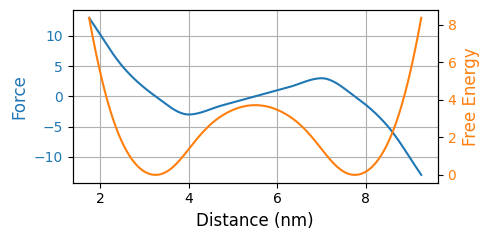

In [7]:
knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (data_cfg.prior.num_knots - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(data_cfg.simulator.x_min - x_plot_margin, data_cfg.simulator.x_max + x_plot_margin, 500)

fig, ax1 = plt.subplots(figsize=(5, 2.5), sharex=True)

x, y_force = eval_force(
    params=true_params,
    x_eval=x_eval,
)
ax1.plot(x, y_force, color='tab:blue', label='Force')
ax1.set_xlabel('Distance (nm)', fontsize=12)
ax1.set_ylabel('Force', color='tab:blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid()

ax2 = ax1.twinx()
x, y_free_energy = eval_free_energy(
    params=true_params,
    x_eval=x_eval,
)
ax2.plot(x, y_free_energy - np.min(y_free_energy), color='tab:orange', label='Free Energy')
ax2.set_ylabel('Free Energy', color='tab:orange', fontsize=12)
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.tight_layout()

## Simulate Observations

In [8]:
with Pool(processes=24, initializer=_init_worker) as pool:
    raw = pool.map(fret_simulator, [true_params] * n_simulations_pool)
results = [r for r in raw if r is not None][:n_observations]
observation = torch.stack(results)

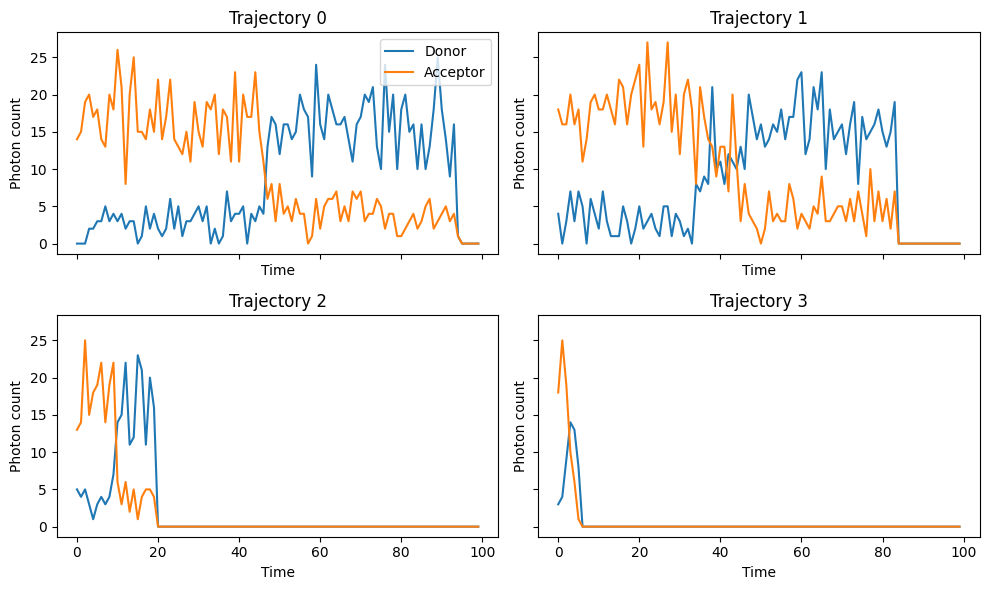

In [9]:
idxs = [0, 1, 2, 3][:observation.shape[0]]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)

for ax, idx in zip(axes.ravel(), idxs):
    ax.plot(bin_along_time(observation[idx, :, 0].numpy(), n_bins=100), label="Donor")
    ax.plot(bin_along_time(observation[idx, :, 1].numpy(), n_bins=100), label="Acceptor")
    ax.set_title(f"Trajectory {idx}")
    ax.set_ylabel("Photon count")
    ax.set_xlabel("Time")

axes[0, 0].legend()
plt.tight_layout()


## Posterior Inference

In [10]:
# Load ensemble members (sibling dirs of cfg_path, each containing a ratio_estimator.pkl).
# Set ensemble_dirs=[cfg_path] for a single-member run.
ensemble_root = Path(cfg_path).parent
ensemble_dirs = sorted(
    p for p in ensemble_root.iterdir()
    if p.is_dir() and (p / "ratio_estimator.pkl").exists() or (p / "last_ratio_estimator.pkl").exists()
)
print(f"Loading {len(ensemble_dirs)} ensemble member(s) from {ensemble_root}")

ratio_estimators = []
for d in ensemble_dirs:
    pkl = d / "ratio_estimator.pkl"
    if not pkl.exists():
        pkl = d / "last_ratio_estimator.pkl"
    with open(pkl, "rb") as f:
        re_i = pickle.load(f)
    re_i.eval()
    ratio_estimators.append(re_i)

if len(ratio_estimators) == 1:
    posterior = build_cached_posterior(
        ratio_estimators[0], prior_posterior, observation,
        num_chains=50, thin=2, device=device,
    )
else:
    posterior = build_cached_ensembled_posterior(
        ratio_estimators, prior_posterior, observation,
        num_chains=50, thin=2, device=device,
    )

samples = posterior.sample(
    (5000,),
    x=observation.cuda(),
    init_strategy_parameters={'num_candidate_samples': 1000},
).cpu()

Loading 5 ensemble member(s) from /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_2/ensemble


Running vectorized MCMC with 50 chains: 100%|██████████| 32500/32500 [02:22<00:00, 228.03it/s]


In [11]:
posterior.set_default_x(observation.cuda())
map_estimate = posterior.map(
    num_iter=10000,
    num_init_samples=1000,
    learning_rate=0.001,
    show_progress_bars=True,
    force_update=True,
)

 Optimizing MAP estimate. Iterations: 10000 / 10000. Performance in iteration 10000: 46.46 (= unnormalized log-prob). Press Ctrl-C to interrupt.

## Results

/tmp/ipykernel_2694852/367872258.py:11: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


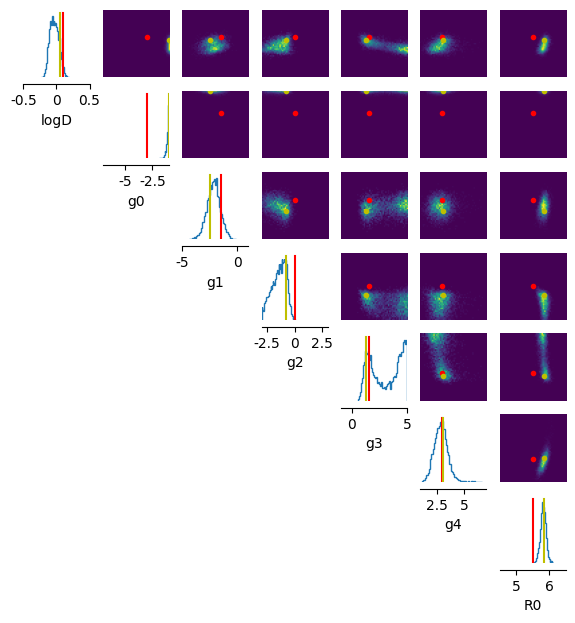

In [12]:
num_knots = data_cfg.prior.num_knots
scale = data_cfg.prior.scale
center = list(data_cfg.prior.center) if data_cfg.prior.center is not None else [0.0] * num_knots

limits = (
    [list(data_cfg.prior.logD_lims)]
    + [[c - scale, c + scale] for c in center]
    + [list(data_cfg.prior.R0_lims)]
)

_ = analysis.pairplot(
    samples,
    figsize=(7, 7),
    points=[true_params[: len(limits)], map_estimate[0].cpu()],
    points_offdiag={"markersize": 6},
    points_colors=["r", "y"],
    limits=limits,
    labels=["logD"] + [f"g{i}" for i in range(num_knots)] + ["R0"],
)


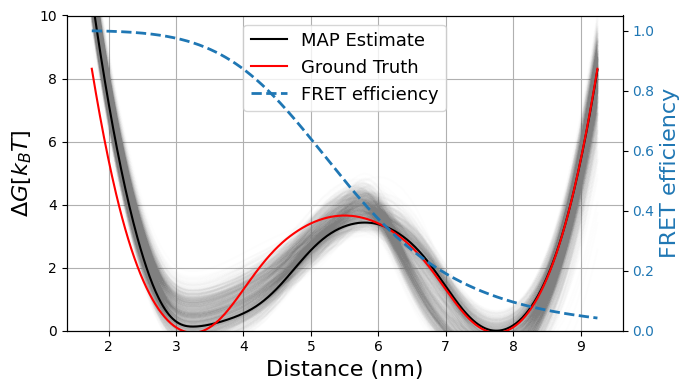

In [13]:
x_min, x_max = -2, 21

fig, ax1 = plt.subplots(figsize=(7, 4))

# Compute MAP free-energy (reference for alignment)
x, y_map = eval_free_energy(params=map_estimate[0].cpu(), x_eval=x_eval)
y_map_shifted = y_map - y_map.min()

# Free-energy samples — align each to MAP via least-squares vertical shift
# Free energy is defined up to an additive constant, so for each sample we find
# the offset c that minimizes ||y_sample + c - y_map_shifted||^2
# Solution: c = mean(y_map_shifted - y_sample)
for i in range(1000):
    x, y = eval_free_energy(params=samples[i], x_eval=x_eval)
    offset = np.mean(y_map_shifted - y)
    ax1.plot(x, y + offset, color="gray", alpha=0.01)

# MAP free-energy
ax1.plot(x, y_map_shifted, color="black", label="MAP Estimate")

# Ground-truth free-energy (aligned to MAP)
x, y_true = eval_free_energy(params=true_params, x_eval=x_eval)
offset_true = np.mean(y_map_shifted - y_true)
ax1.plot(x, y_true + offset_true, color="r", label="Ground Truth")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
ax1.set_ylim(0, 10)
ax1.grid()

# Secondary axis: FRET efficiency
ax2 = ax1.twinx()
R0 = float(true_params[6])
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0) ** 6)
E[x_eval <= 0] = np.nan

ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label="FRET efficiency")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=13, loc="best")

plt.tight_layout()

## Simulation-Based Calibration (SBC)

Test posterior calibration across different numbers of observation trials. For each trial count, we:
1. Draw parameters from the prior
2. Simulate observations with those parameters
3. Sample from the posterior conditioned on the observations
4. Compute the rank of the true parameters among the posterior samples

Well-calibrated posteriors produce uniformly distributed ranks.

In [14]:
from collections import defaultdict

def pregenerate_sbc_simulations(
    n_trials, n_sbc_runs, prior_sim, simulator_fn, n_attempts_per_run=None, n_workers=24,
):
    """Pre-generate all SBC simulations in a single Pool."""
    if n_attempts_per_run is None:
        n_attempts_per_run = max(n_trials * 3, 5)

    # 1. Sample all thetas upfront
    thetas = [prior_sim.sample((1,)).squeeze(0).cpu().double() for _ in range(n_sbc_runs)]

    # 2. Build flat task list: each theta repeated n_attempts_per_run times
    tasks = []
    task_run_idx = []
    for run_idx, theta in enumerate(thetas):
        tasks.extend([theta] * n_attempts_per_run)
        task_run_idx.extend([run_idx] * n_attempts_per_run)

    # 3. Single pool, one map call
    print(f"  Simulating {len(tasks)} total tasks across {n_workers} workers...")
    with Pool(processes=n_workers, initializer=_init_worker) as pool:
        raw_results = pool.map(simulator_fn, tasks)

    # 4. Group by run, filter failures, keep n_trials
    grouped = defaultdict(list)
    for idx, result in zip(task_run_idx, raw_results):
        if result is not None:
            grouped[idx].append(result[0])

    sbc_data = []
    for run_idx in range(n_sbc_runs):
        results = grouped[run_idx][:n_trials]
        if len(results) >= n_trials:
            sbc_data.append((thetas[run_idx], torch.stack(results)))

    return sbc_data


def precompute_embeddings(sbc_data, ratio_estimator, device, batch_size=100):
    """
    Pre-compute all observation embeddings in batches.

    Returns a list of pre-computed embedding tensors (one per SBC run),
    each of shape (n_trials, embed_dim).
    """
    all_obs = [obs for _, obs in sbc_data]

    embeddings = []
    with torch.no_grad():
        for i in range(0, len(all_obs), batch_size):
            batch = torch.cat(
                [o.reshape(-1, *ratio_estimator.x_shape) for o in all_obs[i:i+batch_size]],
                dim=0,
            ).to(device)
            emb = ratio_estimator.embedding_net_x(batch)
            embeddings.append(emb.cpu())

    all_emb = torch.cat(embeddings, dim=0)
    n_trials = all_obs[0].shape[0]
    per_run = all_emb.split(n_trials)

    return list(per_run)


def run_sbc_from_pregenerated(
    sbc_data, n_posterior_samples, prior_posterior, ratio_estimator,
    num_chains, thin, device, embedding_batch_size=100,
):
    """Run MCMC inference on pre-generated simulation data with batched embeddings."""
    n_posterior_params = prior_posterior.sample((1,)).shape[-1]

    # Install the fast combine_theta_and_x monkeypatch once
    _original_combine = ratio_estimator.__class__.combine_theta_and_x

    def _fast_combine(self, theta, x):
        theta_shape_size = math.prod(self.theta_shape)
        n_iid = self._x_cached_embedded.shape[0]
        if theta.numel() % theta_shape_size != 0:
            return _original_combine(self, theta, x)
        n = theta.numel() // theta_shape_size
        if n % n_iid != 0:
            return _original_combine(self, theta, x)
        embedded_theta = self.embedding_net_theta(theta.reshape(n, *self.theta_shape))
        embedded_x = self._x_cached_embedded.repeat_interleave(n // n_iid, dim=0)
        prefix_shape = theta.shape[: -len(self.theta_shape)]
        return torch.cat([embedded_theta, embedded_x], dim=-1).reshape(*prefix_shape, -1)

    ratio_estimator.combine_theta_and_x = types.MethodType(_fast_combine, ratio_estimator)

    # Pre-compute ALL embeddings in batches
    print(f"  Pre-computing embeddings in batches of {embedding_batch_size}...")
    all_embeddings = precompute_embeddings(
        sbc_data, ratio_estimator, device, batch_size=embedding_batch_size
    )

    all_thetas = []
    all_ranks = []

    for (theta_full, obs), cached_emb in tqdm(
        zip(sbc_data, all_embeddings), total=len(sbc_data), desc="SBC inference"
    ):
        # Swap cached embedding (no embedding_net_x call needed)
        ratio_estimator._x_cached_embedded = cached_emb.to(device)

        # Build potential and posterior (lightweight - no embedding computation)
        potential, tf = ratio_estimator_based_potential(
            ratio_estimator, prior_posterior, obs.to(device)
        )
        posterior = MCMCPosterior(
            potential, proposal=prior_posterior, theta_transform=tf,
            num_chains=num_chains, thin=thin, method="slice_np_vectorized",
        )

        samples = posterior.sample(
            (n_posterior_samples,),
            x=obs.to(device),
            init_strategy_parameters={"num_candidate_samples": 500},
        ).cpu()

        theta_reduced = theta_full[:n_posterior_params].float()
        ranks = (samples.float() < theta_reduced.unsqueeze(0)).sum(dim=0)
        all_thetas.append(theta_reduced)
        all_ranks.append(ranks)

    return torch.stack(all_thetas), torch.stack(all_ranks)

In [15]:
sbc_results = {}
for n_trials in sbc_trial_counts:
    print(f"Pre-generating simulations for n_trials={n_trials}...")
    sbc_data = pregenerate_sbc_simulations(
        n_trials=n_trials,
        n_sbc_runs=sbc_num_runs,
        prior_sim=prior_sim,
        simulator_fn=_fret_simulator,
        n_workers=sbc_n_workers,
    )
    print(f"  Generated {len(sbc_data)}/{sbc_num_runs} valid runs")

    thetas, ranks = run_sbc_from_pregenerated(
        sbc_data=sbc_data,
        n_posterior_samples=sbc_num_posterior_samples,
        prior_posterior=prior_posterior,
        ratio_estimator=ratio_estimator,
        num_chains=sbc_num_mcmc_chains,
        thin=sbc_mcmc_thin,
        device=device,
    )
    sbc_results[n_trials] = {"thetas": thetas, "ranks": ranks}
    print(f"n_trials={n_trials}: completed {ranks.shape[0]} SBC runs")

Pre-generating simulations for n_trials=1...
  Simulating 5000 total tasks across 24 workers...


KeyboardInterrupt: 

In [ ]:
# Compare SBC rank ECDFs across different trial counts
fig, axes = plt.subplots(
    len(sbc_trial_counts), 1,
    figsize=(10, 4 * len(sbc_trial_counts)),
    squeeze=False,
)

for ax, n_trials in zip(axes.ravel(), sbc_trial_counts):
    ranks = sbc_results[n_trials]["ranks"]
    sbc_rank_plot(
        ranks,
        num_posterior_samples=sbc_num_posterior_samples,
        plot_type="cdf",
        ax=ax,
    )
    ax.set_title(f"SBC Rank ECDF (n_trials = {n_trials})")

plt.tight_layout()

In [ ]:
# KS test for uniformity of ranks (per parameter, per trial count)
from scipy.stats import kstest

n_params = true_params.shape[0]
for n_trials in sbc_trial_counts:
    ranks = sbc_results[n_trials]["ranks"]
    normalized = ranks.float() / sbc_num_posterior_samples
    ks_pvals = [kstest(normalized[:, p].numpy(), "uniform").pvalue for p in range(n_params)]
    n_pass = sum(p > 0.05 for p in ks_pvals)
    print(
        f"n_trials={n_trials:3d}: "
        f"mean KS p-val={np.mean(ks_pvals):.3f}, "
        f"min={np.min(ks_pvals):.3f}, "
        f"params passing (p>0.05): {n_pass}/{n_params}"
    )

In [ ]:
# Save SBC results (optional — useful given computational cost)
with open(cfg_path + "sbc_results.pkl", "wb") as f:
    pickle.dump(sbc_results, f)
print(f"Saved SBC results to {cfg_path}sbc_results.pkl")